<a href="https://colab.research.google.com/github/kashmala-mahsud/System-7-Repository/blob/main/house_price_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [ ]:
df1 = pd.read_csv("/content/data.csv")
df2 = pd.read_csv("/content/output.csv")

In [ ]:
df = pd.concat([df1, df2], ignore_index=True)

In [ ]:
df.head(5)

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA
2,2014-05-02 00:00:00,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,USA
3,2014-05-02 00:00:00,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,USA
4,2014-05-02 00:00:00,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,USA


In [ ]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9200 entries, 0 to 9199
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           9200 non-null   object 
 1   price          9200 non-null   float64
 2   bedrooms       9200 non-null   float64
 3   bathrooms      9200 non-null   float64
 4   sqft_living    9200 non-null   int64  
 5   sqft_lot       9200 non-null   int64  
 6   floors         9200 non-null   float64
 7   waterfront     9200 non-null   int64  
 8   view           9200 non-null   int64  
 9   condition      9200 non-null   int64  
 10  sqft_above     9200 non-null   int64  
 11  sqft_basement  9200 non-null   int64  
 12  yr_built       9200 non-null   int64  
 13  yr_renovated   9200 non-null   int64  
 14  street         9200 non-null   object 
 15  city           9200 non-null   object 
 16  statezip       9200 non-null   object 
 17  country        9200 non-null   object 
dtypes: float

In [ ]:
df.duplicated().sum()

np.int64(4598)

In [ ]:
df.columns[df.columns.duplicated()]

Index([], dtype='object')

In [ ]:
df = df.drop_duplicates()

In [ ]:
df.duplicated().sum()

np.int64(0)

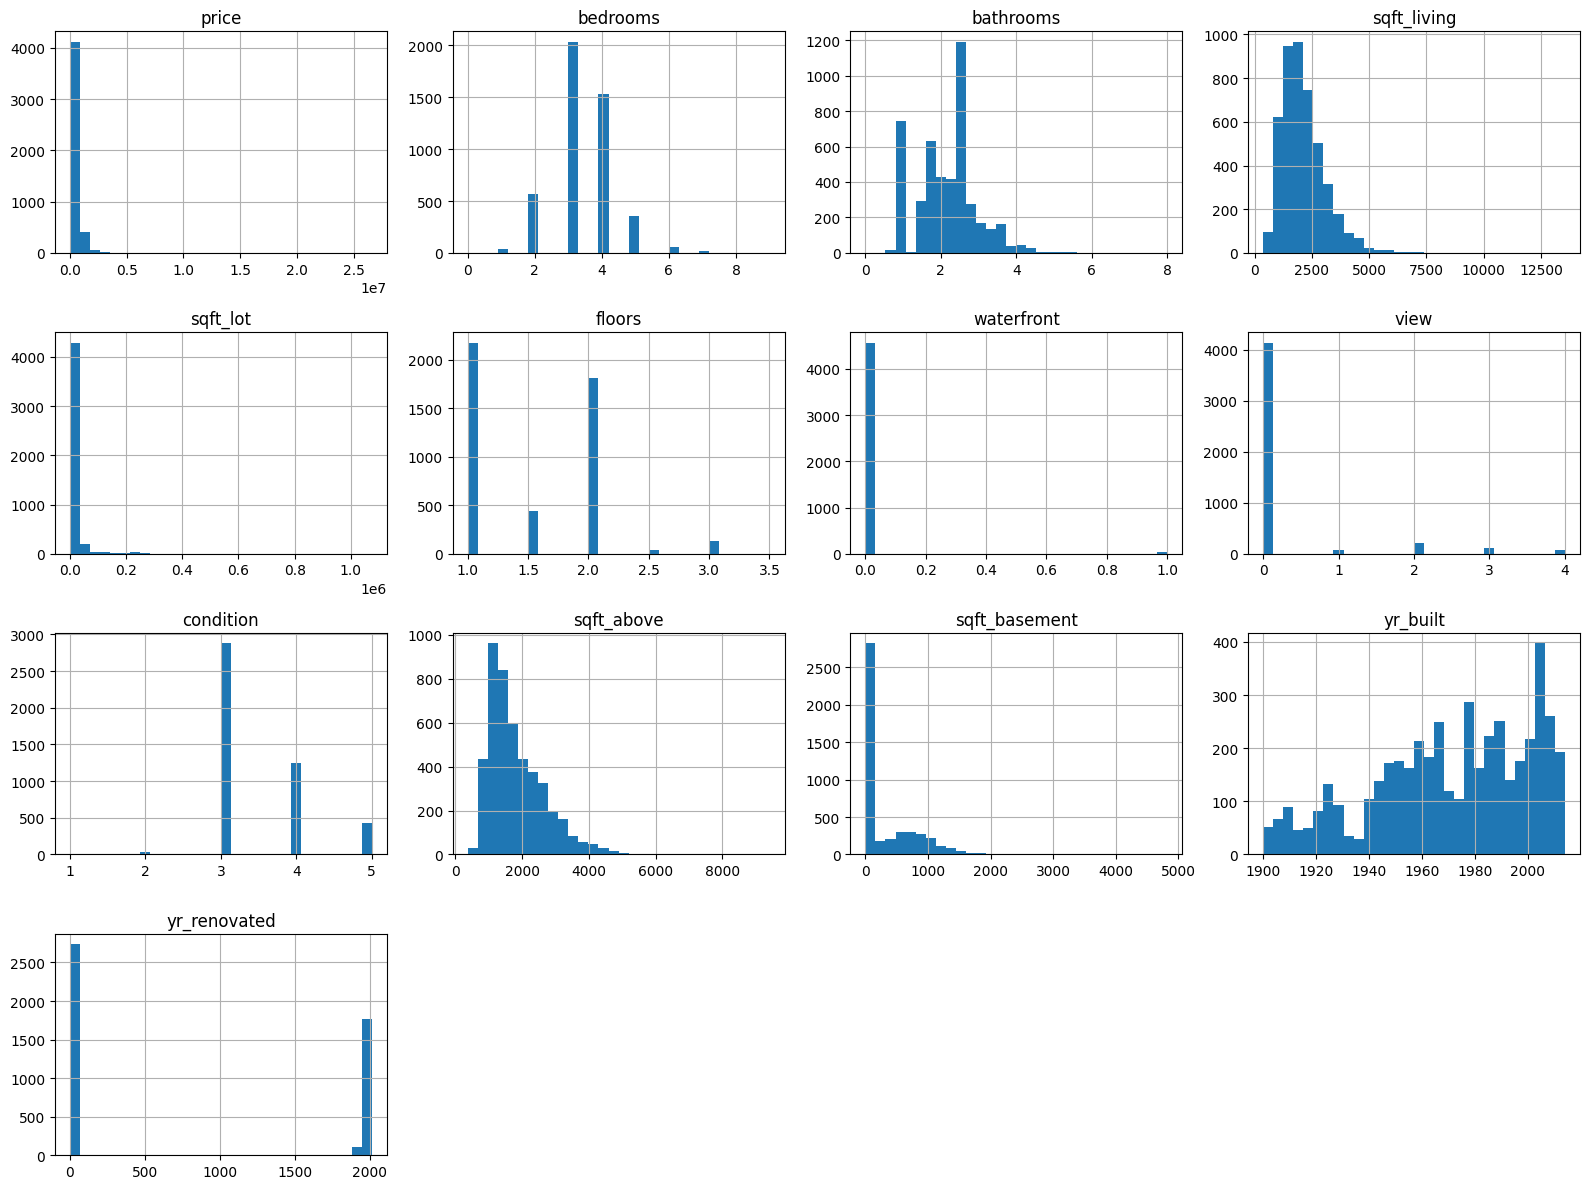

In [ ]:
import matplotlib.pyplot as plt

df.hist(figsize=(16, 12), bins=30)
plt.tight_layout()
plt.show()

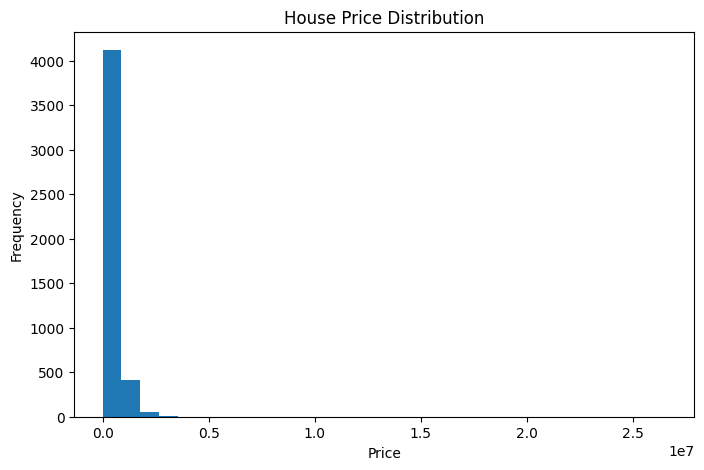

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(df['price'], bins=30)
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.title('House Price Distribution')
plt.show()

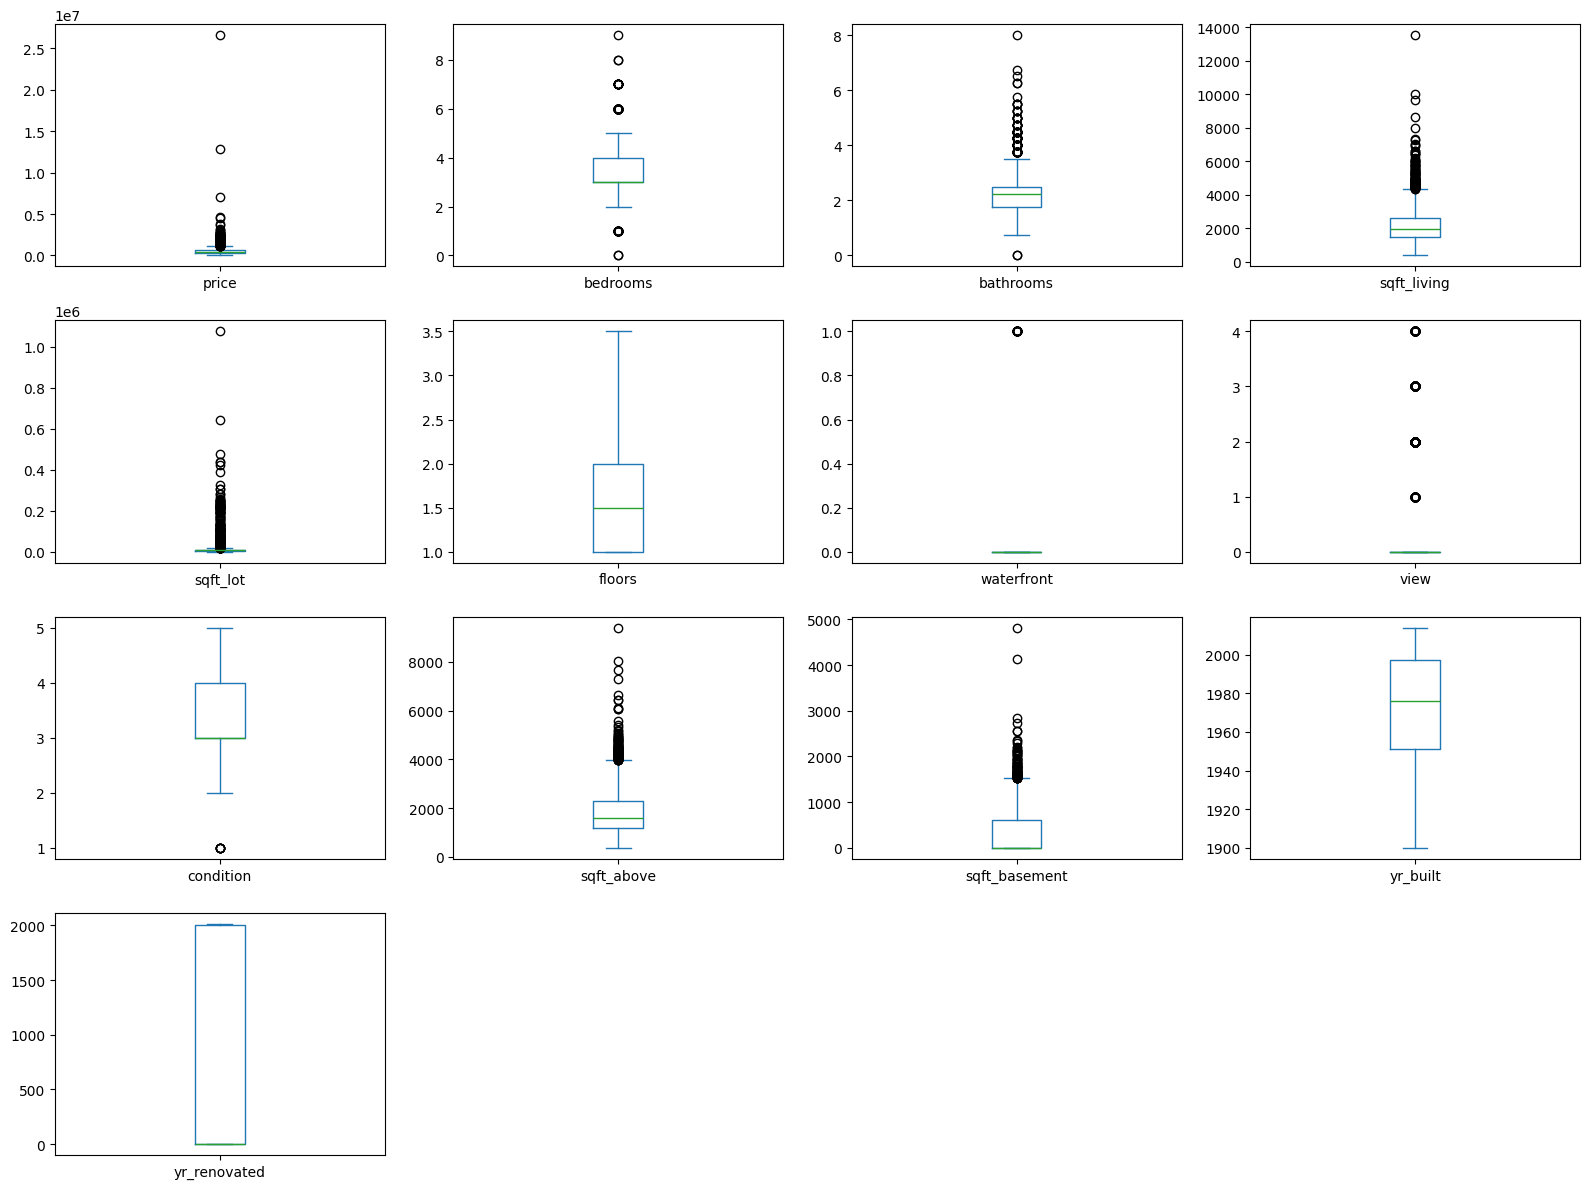

In [ ]:
df.select_dtypes(include='number').plot(
    kind='box',
    subplots=True,
    layout=(4, 4),
    figsize=(16, 12),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

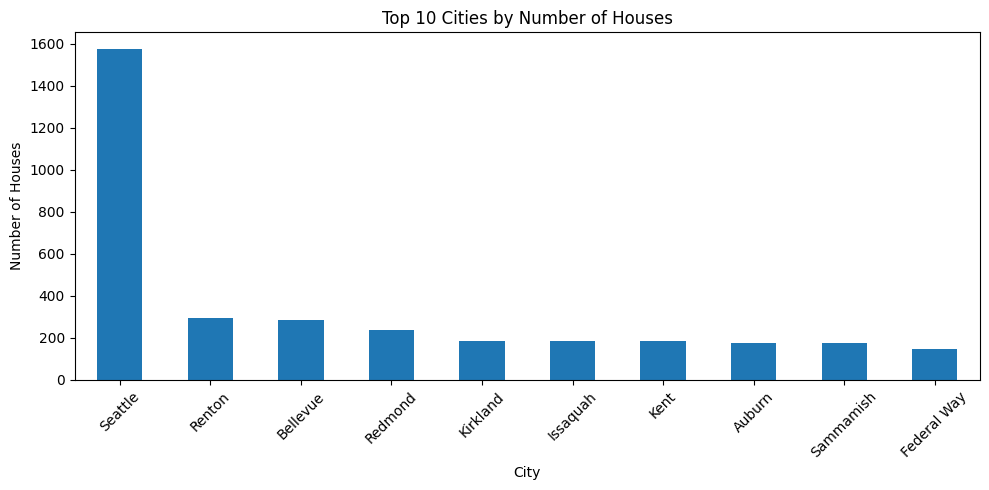

In [ ]:
df['city'].value_counts().head(10).plot(kind='bar', figsize=(10, 5))

plt.xlabel('City')
plt.ylabel('Number of Houses')
plt.title('Top 10 Cities by Number of Houses')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
print("Bedrooms:")
print(df['bedrooms'].value_counts().sort_index())

print("\nBathrooms:")
print(df['bathrooms'].value_counts().sort_index())

print("\nPrice:")
print(df['price'].describe())

print("\nLiving Area:")
print(df['sqft_living'].describe())

Bedrooms:
bedrooms
0.0       2
1.0      39
2.0     566
3.0    2033
4.0    1531
5.0     353
6.0      61
7.0      14
8.0       2
9.0       1
Name: count, dtype: int64

Bathrooms:
bathrooms
0.00       2
0.75      17
1.00     744
1.25       3
1.50     291
1.75     629
2.00     427
2.25     419
2.50    1190
2.75     276
3.00     167
3.25     136
3.50     162
3.75      37
4.00      23
4.25      23
4.50      29
4.75       7
5.00       6
5.25       4
5.50       4
5.75       1
6.25       2
6.50       1
6.75       1
8.00       1
Name: count, dtype: int64

Price:
count    4.602000e+03
mean     5.519126e+05
std      5.637384e+05
min      0.000000e+00
25%      3.226250e+05
50%      4.609435e+05
75%      6.549875e+05
max      2.659000e+07
Name: price, dtype: float64

Living Area:
count     4602.000000
mean      2138.888744
std        963.256877
min        370.000000
25%       1460.000000
50%       1980.000000
75%       2620.000000
max      13540.000000
Name: sqft_living, dtype: float64


In [ ]:
cols = ['price', 'sqft_living', 'sqft_lot',
        'sqft_above', 'sqft_basement']

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"{col}: {len(outliers)} outliers")
    print(f"Lower limit: {lower:.2f}")
    print(f"Upper limit: {upper:.2f}\n")

price: 240 outliers
Lower limit: -175918.75
Upper limit: 1153531.25

sqft_living: 129 outliers
Lower limit: -280.00
Upper limit: 4360.00

sqft_lot: 542 outliers
Lower limit: -4000.00
Upper limit: 20000.00

sqft_above: 116 outliers
Lower limit: -475.00
Upper limit: 3965.00

sqft_basement: 82 outliers
Lower limit: -915.00
Upper limit: 1525.00



In [ ]:
df.loc[
    (df['price'] <= 0) |
    (df['bedrooms'] == 0) |
    (df['bathrooms'] == 0),
    ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'city']
]

,price,bedrooms,bathrooms,sqft_living,city
2365,1095000.0,0.0,0.00,3064,Seattle
3209,1295648.0,0.0,0.00,4810,Redmond
4354,0.0,3.0,1.75,1490,Federal Way
4356,0.0,4.0,2.75,2600,Seattle
4357,0.0,6.0,2.75,3200,Burien
4358,0.0,5.0,3.50,3480,Issaquah
4361,0.0,5.0,1.50,1500,Burien
4362,0.0,4.0,4.00,3680,Sammamish
4374,0.0,2.0,2.50,2200,Enumclaw
4376,0.0,4.0,2.25,2170,Normandy Park


In [ ]:
df[df['price'] > 1153531.25][
    ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'city']
].sort_values('price', ascending=False).head(20)

,price,bedrooms,bathrooms,sqft_living,city
4350,2.659000e+07,3.0,2.00,1180,Kent
4346,1.289900e+07,3.0,2.50,2190,Seattle
2286,7.062500e+06,5.0,4.50,10040,Bellevue
2654,4.668000e+06,5.0,6.75,9640,Mercer Island
2761,4.489000e+06,4.0,3.00,6430,Bellevue
3729,3.800000e+06,5.0,5.50,7050,Clyde Hill
1637,3.710000e+06,4.0,3.50,5550,Medina
252,3.200000e+06,7.0,4.50,6210,Seattle
1567,3.100000e+06,6.0,4.25,6980,Mercer Island
2772,3.000000e+06,4.0,4.25,4850,Kirkland


In [ ]:
df = df[df['price'] > 0].copy()

In [ ]:
print((df['price'] == 0).sum())

0


In [ ]:
df[(df['bedrooms'] == 0) | (df['bathrooms'] == 0)]

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
2365,2014-06-12 00:00:00,1095000.0,0.0,0.0,3064,4764,3.5,0,2,3,3064,0,1990,2009,814 E Howe St,Seattle,WA 98102,USA
3209,2014-06-24 00:00:00,1295648.0,0.0,0.0,4810,28008,2.0,0,0,3,4810,0,1990,2009,20418 NE 64th Pl,Redmond,WA 98053,USA


In [ ]:
df.nlargest(20, 'price')[
    ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'city']
]

,price,bedrooms,bathrooms,sqft_living,sqft_lot,city
4350,2.659000e+07,3.0,2.00,1180,7793,Kent
4346,1.289900e+07,3.0,2.50,2190,11394,Seattle
2286,7.062500e+06,5.0,4.50,10040,37325,Bellevue
2654,4.668000e+06,5.0,6.75,9640,13068,Mercer Island
2761,4.489000e+06,4.0,3.00,6430,27517,Bellevue
3729,3.800000e+06,5.0,5.50,7050,42840,Clyde Hill
1637,3.710000e+06,4.0,3.50,5550,28078,Medina
252,3.200000e+06,7.0,4.50,6210,8856,Seattle
1567,3.100000e+06,6.0,4.25,6980,15682,Mercer Island
2772,3.000000e+06,4.0,4.25,4850,12445,Kirkland


In [ ]:
import numpy as np

df.loc[df['bedrooms'] == 0, 'bedrooms'] = np.nan
df.loc[df['bathrooms'] == 0, 'bathrooms'] = np.nan

In [ ]:
df = df[df['price'] > 0].copy()

In [ ]:
print("Rows:", df.shape[0])
print("Zero bedrooms:", (df['bedrooms'] == 0).sum())
print("Zero bathrooms:", (df['bathrooms'] == 0).sum())
print("Zero prices:", (df['price'] == 0).sum())
print("Missing values:\n", df.isnull().sum())

Rows: 4553
Zero bedrooms: 0
Zero bathrooms: 0
Zero prices: 0
Missing values:
 date             0
price            0
bedrooms         2
bathrooms        2
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64


In [ ]:
df['bedrooms'] = df['bedrooms'].fillna(df['bedrooms'].median())
df['bathrooms'] = df['bathrooms'].fillna(df['bathrooms'].median())

In [ ]:
print(df.isnull().sum())
print(df.shape)

date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64
(4553, 18)


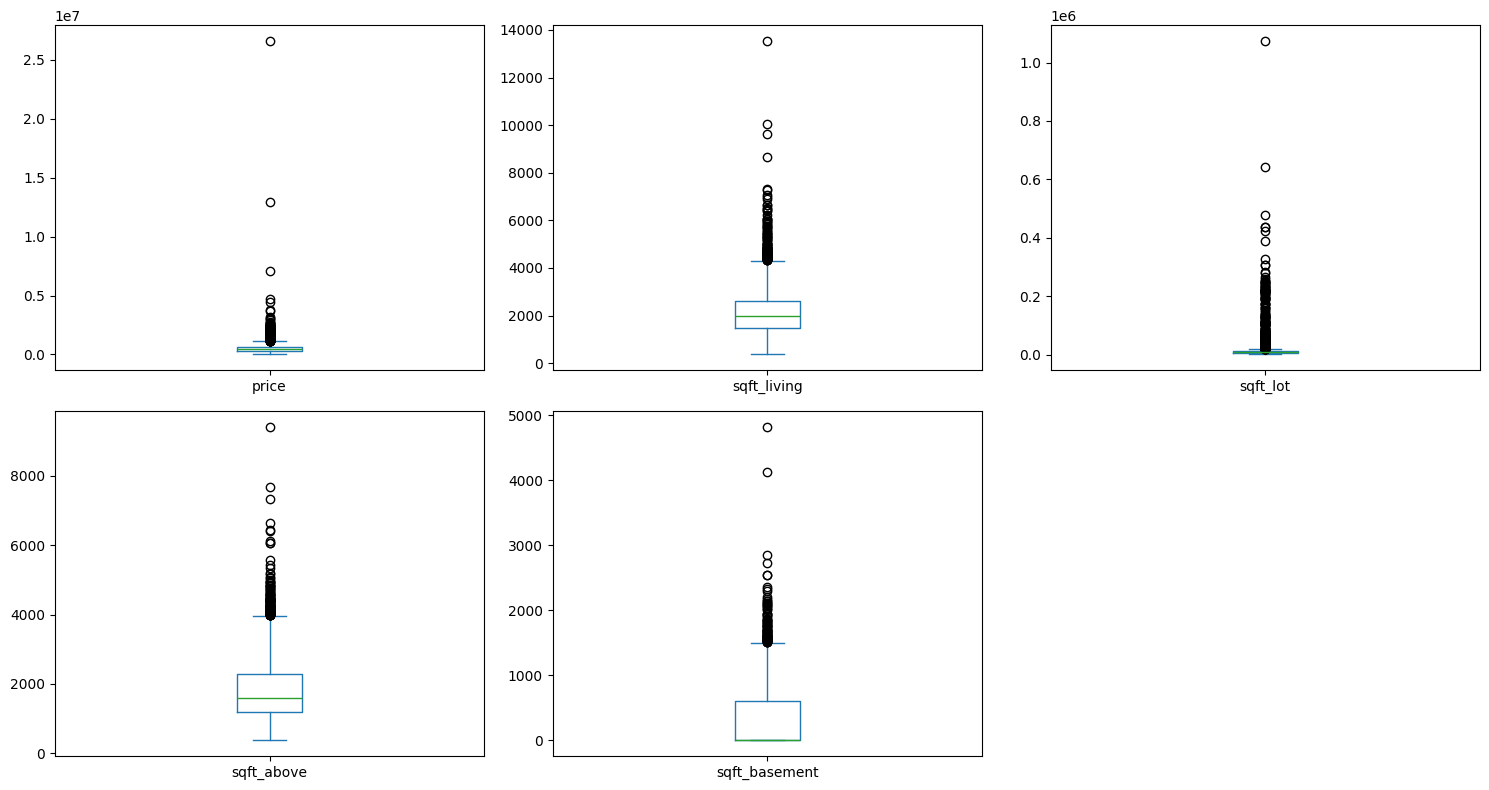

In [ ]:
import matplotlib.pyplot as plt

cols = ['price', 'sqft_living', 'sqft_lot',
        'sqft_above', 'sqft_basement']

df[cols].plot(
    kind='box',
    subplots=True,
    layout=(2, 3),
    figsize=(15, 8),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

In [ ]:
cols = ['price', 'sqft_living', 'sqft_lot',
        'sqft_above', 'sqft_basement']

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(f"{col}: {count} outliers")

price: 240 outliers
sqft_living: 128 outliers
sqft_lot: 540 outliers
sqft_above: 111 outliers
sqft_basement: 83 outliers


In [ ]:
cols = ['price', 'sqft_living', 'sqft_lot',
        'sqft_above', 'sqft_basement']

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    upper = Q3 + 1.5 * IQR

    print(f"\n{col} outliers:")
    print(df[df[col] > upper][col].sort_values(ascending=False).head(10))


price outliers:
4350    26590000.0
4346    12899000.0
2286     7062500.0
2654     4668000.0
2761     4489000.0
3729     3800000.0
1637     3710000.0
252      3200000.0
1567     3100000.0
2772     3000000.0
Name: price, dtype: float64

sqft_living outliers:
122     13540
2286    10040
2654     9640
2328     8670
4138     7320
462      7270
3729     7050
1567     6980
2967     6900
3559     6640
Name: sqft_living, dtype: int64

sqft_lot outliers:
1078    1074218
2480     641203
3487     478288
879      435600
375      435600
1539     423838
3056     389126
240      327135
122      307752
4353     306848
Name: sqft_lot, dtype: int64

sqft_above outliers:
122     9410
2286    7680
4138    7320
3559    6640
2761    6430
462     6420
2328    6120
4283    6070
2731    6050
1302    5584
Name: sqft_above, dtype: int64

sqft_basement outliers:
2654    4820
122     4130
1602    2850
3729    2730
2328    2550
839     2550
2286    2360
970     2330
2057    2300
1637    2200
Name: sqft_basement, dt

In [ ]:
check_indices = [122, 2286, 2654, 3729, 4350, 4346]

df.loc[check_indices, [
    'price', 'bedrooms', 'bathrooms',
    'sqft_living', 'sqft_lot', 'floors',
    'sqft_above', 'sqft_basement',
    'yr_built', 'yr_renovated', 'city'
]]

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,sqft_above,sqft_basement,yr_built,yr_renovated,city
122,2280000.0,7.0,8.00,13540,307752,3.0,9410,4130,1999,0,Redmond
2286,7062500.0,5.0,4.50,10040,37325,2.0,7680,2360,1940,2001,Bellevue
2654,4668000.0,5.0,6.75,9640,13068,1.0,4820,4820,1983,2009,Mercer Island
3729,3800000.0,5.0,5.50,7050,42840,1.0,4320,2730,1978,2000,Clyde Hill
4350,26590000.0,3.0,2.00,1180,7793,1.0,1180,0,1992,0,Kent
4346,12899000.0,3.0,2.50,2190,11394,1.0,1550,640,1956,2001,Seattle


In [ ]:
df['price_per_sqft'] = df['price'] / df['sqft_living']

df.loc[[122, 2286, 2654, 3729, 4350, 4346],
       ['price', 'sqft_living', 'price_per_sqft', 'city']]

,price,sqft_living,price_per_sqft,city
122,2280000.0,13540,168.389956,Redmond
2286,7062500.0,10040,703.436255,Bellevue
2654,4668000.0,9640,484.232365,Mercer Island
3729,3800000.0,7050,539.007092,Clyde Hill
4350,26590000.0,1180,22533.898305,Kent
4346,12899000.0,2190,5889.954338,Seattle


In [ ]:
df['price_per_sqft'].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

,price_per_sqft
count,4553.000000
mean,268.785680
std,358.292865
min,10.000000
25%,182.926829
50%,245.424837
75%,315.789474
90%,403.230147
95%,467.116332
99%,618.498680


In [ ]:
df.nlargest(10, 'price_per_sqft')[
    ['price', 'sqft_living', 'price_per_sqft', 'city', 'street']
]

,price,sqft_living,price_per_sqft,city,street
4350,2.659000e+07,1180,22533.898305,Kent,12005 SE 219th Ct
4346,1.289900e+07,2190,5889.954338,Seattle,5426 40th Ave W
4348,2.199900e+06,1120,1964.196429,Covington,19009-19021 SE 266th St
4465,2.560498e+06,1710,1497.367446,Seattle,2826 21st Ave W
4347,2.110000e+06,2100,1004.761905,Tukwila,14070 Military Rd S
404,2.400000e+06,3000,800.000000,Sammamish,East Lake Sammamish Trail
478,1.200000e+06,1560,769.230769,Mercer Island,3603 W Mercer Way
3778,2.760000e+05,370,745.945946,Seattle,2508 NW 67th St
3923,1.755000e+06,2360,743.644068,Seattle,1242 15th Ave E
1186,1.180500e+06,1610,733.229814,Seattle,1015 36th Ave E


In [ ]:
df.loc[[4350, 4346, 4348, 4465, 4347],
       ['price', 'bedrooms', 'bathrooms',
        'sqft_living', 'sqft_lot', 'city', 'street']]

,price,bedrooms,bathrooms,sqft_living,sqft_lot,city,street
4350,2.659000e+07,3.0,2.0,1180,7793,Kent,12005 SE 219th Ct
4346,1.289900e+07,3.0,2.5,2190,11394,Seattle,5426 40th Ave W
4348,2.199900e+06,4.0,1.5,1120,5427,Covington,19009-19021 SE 266th St
4465,2.560498e+06,3.0,2.5,1710,1664,Seattle,2826 21st Ave W
4347,2.110000e+06,4.0,1.0,2100,9200,Tukwila,14070 Military Rd S


In [ ]:
df['date'] = pd.to_datetime(df['date'], errors='coerce')

df['sale_year'] = df['date'].dt.year
df['sale_month'] = df['date'].dt.month

df = df.drop(columns=['date'])

In [ ]:
df = df.drop(columns=['street', 'price_per_sqft'], errors='ignore')

In [ ]:
df = pd.get_dummies(
    df,
    columns=['city', 'statezip', 'country'],
    drop_first=True,
    dtype=int
)

In [ ]:
df.head()
df.shape
df.dtypes

,0
price,float64
bedrooms,float64
bathrooms,float64
sqft_living,int64
sqft_lot,int64
...,...
statezip_WA 98188,int64
statezip_WA 98198,int64
statezip_WA 98199,int64
statezip_WA 98288,int64


In [ ]:
X = df.drop(columns=['price'])
y = df['price']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3642, 133)
Testing data: (911, 133)


In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 145743.53550448205
RMSE: 979636.8159160727
R2 Score: 0.07809814268990312


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("R2 Score:", r2_score(y_test, rf_pred))

MAE: 144647.98072924977
RMSE: 984407.9156340301
R2 Score: 0.06909644627543443


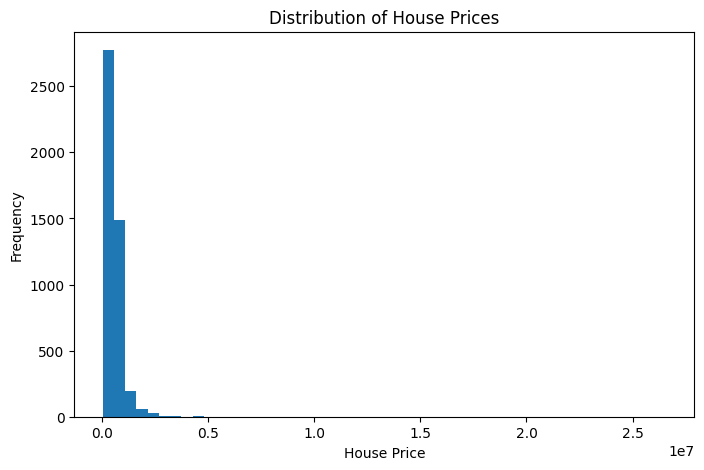

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(df['price'], bins=50)
plt.xlabel('House Price')
plt.ylabel('Frequency')
plt.title('Distribution of House Prices')
plt.show()

In [ ]:
df['price'].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
)

,price
count,4.553000e+03
mean,5.578523e+05
std,5.638331e+05
min,7.800000e+03
50%,4.650000e+05
75%,6.575000e+05
90%,9.044000e+05
95%,1.187001e+06
99%,2.015560e+06
max,2.659000e+07


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

X = df.drop(columns=['price'])
y = np.log1p(df['price'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_log = LinearRegression()
model_log.fit(X_train, y_train)

pred_log = model_log.predict(X_test)

y_test_price = np.expm1(y_test)
pred_price = np.expm1(pred_log)

print("MAE:", mean_absolute_error(y_test_price, pred_price))
print("RMSE:", np.sqrt(mean_squared_error(y_test_price, pred_price)))
print("R2 Score:", r2_score(y_test_price, pred_price))

MAE: 155804.68403437315
RMSE: 1165318.5352846812
R2 Score: -0.30449915583116915


In [ ]:
comparison = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': model.predict(X_test)
})

comparison['Error'] = (
    comparison['Actual Price'] - comparison['Predicted Price']
)

print(comparison.head(10))

      Actual Price  Predicted Price         Error
471      14.018452     1.301942e+06 -1.301928e+06
1971     12.873905     4.519490e+05 -4.519362e+05
23       13.325306     5.905286e+05 -5.905152e+05
2702     13.224922     3.140774e+05 -3.140642e+05
135      13.329379     6.252525e+05 -6.252391e+05
3303     12.945151     4.240776e+05 -4.240646e+05
3337     14.119313     1.159710e+06 -1.159696e+06
4206     12.631344     3.520771e+05 -3.520644e+05
3128     12.694656     2.312640e+05 -2.312513e+05
3262     12.706699     2.039267e+05 -2.039140e+05


In [ ]:
X = df.drop(columns=['price'])
y = df['price']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model.fit(X_train, y_train)

LinearRegression()

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df.drop(columns=['price', 'price_per_sqft'], errors='ignore')
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

comparison = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': predictions
})

comparison['Error'] = (
    comparison['Actual Price'] - comparison['Predicted Price']
)

print(comparison.head(10))

      Actual Price  Predicted Price          Error
471      1225000.0     1.301942e+06  -76941.892322
1971      390000.0     4.519490e+05  -61949.043175
23        612500.0     5.905286e+05   21971.436697
2702      554000.0     3.140774e+05  239922.587548
135       615000.0     6.252525e+05  -10252.466150
3303      418800.0     4.240776e+05   -5277.567554
3337     1355000.0     1.159710e+06  195290.082377
4206      306000.0     3.520771e+05  -46077.074119
3128      326000.0     2.312640e+05   94735.988124
3262      329950.0     2.039267e+05  126023.280006


In [ ]:
print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R2 Score:", r2_score(y_test, predictions))

MAE: 145743.53550448205
RMSE: 979636.8159160727
R2 Score: 0.07809814268990312


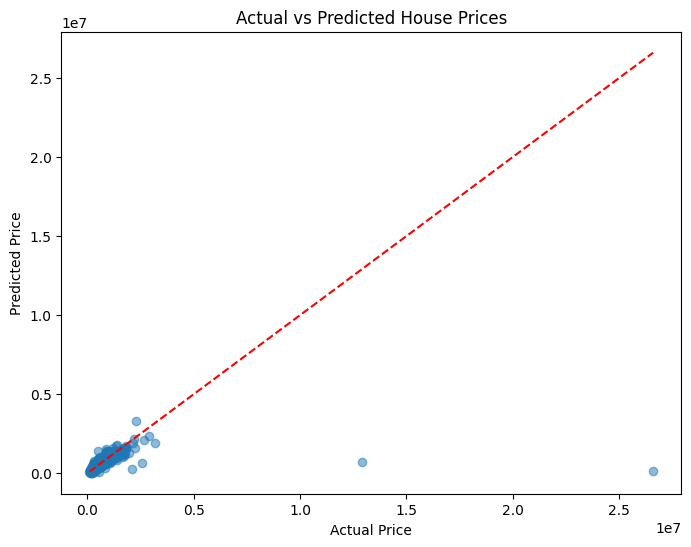

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, predictions, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted House Prices')
plt.show()

In [ ]:
comparison = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': predictions
})

comparison['Absolute Error'] = abs(
    comparison['Actual Price'] - comparison['Predicted Price']
)

comparison = comparison.sort_values(
    'Absolute Error', ascending=False
)

print(comparison.head(10))

      Actual Price  Predicted Price  Absolute Error
4350  2.659000e+07     1.751531e+05    2.641485e+07
4346  1.289900e+07     7.325667e+05    1.216643e+07
4465  2.560498e+06     6.221400e+05    1.938358e+06
4347  2.110000e+06     2.471365e+05    1.862863e+06
252   3.200000e+06     1.932416e+06    1.267584e+06
122   2.280000e+06     3.301875e+06    1.021875e+06
1042  4.900000e+05     1.424255e+06    9.342552e+05
589   8.600000e+05     1.530198e+06    6.701976e+05
3964  1.738000e+06     1.069463e+06    6.685370e+05
2364  2.250000e+06     1.587756e+06    6.622438e+05


In [ ]:
# Original row indices ko use karke extreme records identify karo
extreme_indices = [4350, 4346]

df_experiment = df.drop(index=extreme_indices, errors='ignore').copy()

X = df_experiment.drop(
    columns=['price', 'price_per_sqft'],
    errors='ignore'
)
y = df_experiment['price']

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_without_extremes = LinearRegression()
model_without_extremes.fit(X_train, y_train)

predictions = model_without_extremes.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R2 Score:", r2_score(y_test, predictions))

MAE: 112492.5043217846
RMSE: 209054.3287891512
R2 Score: 0.7080703628780562


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, rf_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_predictions)))
print("R2 Score:", r2_score(y_test, rf_predictions))

MAE: 111902.60145068986
RMSE: 225699.05793413057
R2 Score: 0.6597333771795817


In [ ]:
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model_without_extremes.coef_
})

importance['Absolute Coefficient'] = abs(
    importance['Coefficient']
)

importance = importance.sort_values(
    'Absolute Coefficient', ascending=False
)

print(importance.head(15))

                Feature    Coefficient  Absolute Coefficient
35          city_Medina  700842.090112         700842.090112
80    statezip_WA 98039  700842.090112         700842.090112
59    statezip_WA 98004  631163.218810         631163.218810
5            waterfront  548849.763861         548849.763861
56    city_Yarrow Point  497392.955442         497392.955442
109   statezip_WA 98112  431219.268264         431219.268264
114   statezip_WA 98119  385151.994119         385151.994119
108   statezip_WA 98109  374334.851841         374334.851841
104   statezip_WA 98105  342193.244373         342193.244373
129   statezip_WA 98198 -315876.573913         315876.573913
23      city_Des Moines  300827.282836         300827.282836
39   city_Normandy Park  279671.830712         279671.830712
36   city_Mercer Island  269498.156581         269498.156581
81    statezip_WA 98040  269498.156581         269498.156581
102   statezip_WA 98102  264021.573592         264021.573592


In [ ]:
numerical_features = [
    'bedrooms', 'bathrooms', 'sqft_living',
    'sqft_lot', 'floors', 'waterfront', 'view',
    'condition', 'sqft_above', 'sqft_basement',
    'yr_built', 'yr_renovated', 'sale_year', 'sale_month'
]

importance[
    importance['Feature'].isin(numerical_features)
].sort_values('Absolute Coefficient', ascending=False)

,Feature,Coefficient,Absolute Coefficient
5,waterfront,5.488498e+05,5.488498e+05
6,view,6.336930e+04,6.336930e+04
4,floors,-3.840662e+04,3.840662e+04
7,condition,2.859838e+04,2.859838e+04
0,bedrooms,-2.629656e+04,2.629656e+04
1,bathrooms,1.385231e+04,1.385231e+04
13,sale_month,6.931157e+03,6.931157e+03
10,yr_built,-2.232395e+02,2.232395e+02
8,sqft_above,1.596730e+02,1.596730e+02
2,sqft_living,9.823394e+01,9.823394e+01


In [ ]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    model_without_extremes,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring='r2'
)

perm_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': result.importances_mean
}).sort_values('Importance', ascending=False)

print(perm_importance.head(15))

                Feature  Importance
8            sqft_above    0.255133
48         city_Seattle    0.146407
2           sqft_living    0.123221
59    statezip_WA 98004    0.074009
5            waterfront    0.047102
16        city_Bellevue    0.035419
6                  view    0.030994
109   statezip_WA 98112    0.028012
104   statezip_WA 98105    0.021085
36   city_Mercer Island    0.020791
81    statezip_WA 98040    0.020791
129   statezip_WA 98198    0.020482
32        city_Kirkland    0.020414
44         city_Redmond    0.018415
23      city_Des Moines    0.016926


In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression
import numpy as np

model_cv = LinearRegression()

scores = cross_val_score(
    model_cv,
    X,
    y,
    cv=5,
    scoring='r2'
)

print("R2 scores:", scores)
print("Mean R2:", scores.mean())
print("Standard Deviation:", scores.std())

R2 scores: [0.80142388 0.79026075 0.76420839 0.78221504 0.61193453]
Mean R2: 0.7500085164516632
Standard Deviation: 0.07009579675788738


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R2:", r2_score(y_test, predictions))

MAE: 112492.5043217846
RMSE: 209054.3287891512
R2: 0.7080703628780562


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Same dataset and same train-test split
X = df_experiment.drop(columns=['price', 'price_per_sqft'], errors='ignore')
y = df_experiment['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Initialize both models
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

# Train and evaluate both models
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R2 Score': r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)
print(results_df.round(2))

               Model       MAE       RMSE  R2 Score
0  Linear Regression  112492.5  209054.33      0.71
1      Random Forest  111902.6  225699.06      0.66


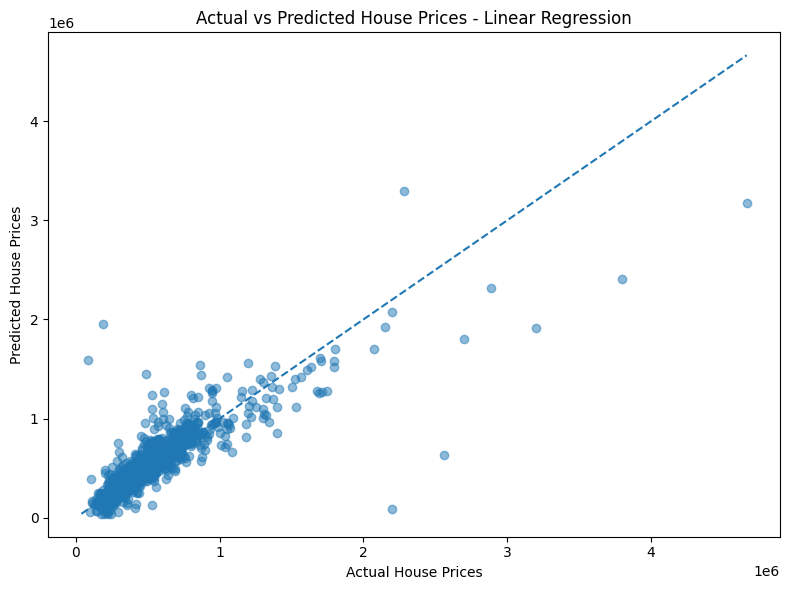

In [ ]:
import matplotlib.pyplot as plt

# Linear Regression predictions
lr_predictions = models['Linear Regression'].predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, lr_predictions, alpha=0.5)

# Perfect prediction reference line
min_price = min(y_test.min(), lr_predictions.min())
max_price = max(y_test.max(), lr_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle='--'
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices - Linear Regression")
plt.tight_layout()
plt.show()